# TP4 : Prédiction de notes d'hôtels à partir de commentaires avec BERT

Ce notebook implémente un modèle BERT pour prédire les évaluations (1-5 étoiles) à partir des commentaires clients.

**Architecture:**
- Modèle de base : ModernBERT (ou BERT standard)
- Approche : Régression ordinale avec CORN (Consistent Rank Logits)
- Pooling : Mean pooling des embeddings

In [1]:
# Imports nécessaires
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import os
import gc
import time
import random

from sklearn.metrics import r2_score, mean_absolute_error
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.utils.data import TensorDataset, DataLoader

# Configuration globale
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

/home/christ/Downloads/Telegram Desktop/M1/M1 Avignon universite/approches neuronales/TP/env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Chargement des données

In [2]:

# Liste des fichiers dans le dossier data
folder = os.listdir('data')
print("Fichiers disponibles:", folder)

# Chargement des données
def load_data(file_path):
    with open(os.path.join('data', file_path), 'r') as f:
        data = pd.read_csv(f)
    return data

data_train = load_data('train_hotel.csv')
data_test = load_data('test_hotel.csv')
data_val = load_data('valid_hotel.csv')

print(f"\nDataset sizes:")
print(f"  Train: {len(data_train)} samples")
print(f"  Validation: {len(data_val)} samples")
print(f"  Test: {len(data_test)} samples")

# Aperçu des données
print("\nAperçu des données:")
print(data_train[['Review', 'Rating']].head(3))

Fichiers disponibles: ['test_hotel.csv', 'train_hotel.csv', 'valid_hotel.csv']

Dataset sizes:
  Train: 18491 samples
  Validation: 1000 samples
  Test: 1000 samples

Aperçu des données:
                                              Review  Rating
0  nice hotel expensive parking got good deal sta...       4
1  ok nothing special charge diamond member hilto...       2
2  nice rooms not 4* experience hotel monaco seat...       3


## 2. Prétraitement et Tokenisation

In [3]:
# Configuration du modèle BERT
model_id = "answerdotai/ModernBERT-base"  # ModernBERT

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_id)

print(f"Modèle chargé: {model_id}")

# Fonction de tokenisation
def tokenize_data(texts, max_length=128):
    """Tokenise les textes avec padding et truncation"""
    return tokenizer(
        texts.tolist(),
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )

# Préparation des labels (conversion 1-5 vers 0-4)
def prepare_labels(df):
    return torch.tensor(df['Rating'].values - 1, dtype=torch.long)

train_labels = prepare_labels(data_train)
val_labels = prepare_labels(data_val)
test_labels = prepare_labels(data_test)

print(f"Labels préparés: train={len(train_labels)}, val={len(val_labels)}, test={len(test_labels)}")

Modèle chargé: answerdotai/ModernBERT-base
Labels préparés: train=18491, val=1000, test=1000


## 3. Architecture du modèle

In [ ]:
class RegressionModel(nn.Module):
    """
    Modèle BERT pour la prédiction de notes
    Utilise CORN (Consistent Rank Logits) pour la régression ordinale
    """
    def __init__(self, model_name="answerdotai/ModernBERT-base", num_classes=5, use_mean_pooling=True, dropout=0.5):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.use_mean_pooling = use_mean_pooling
        hidden_size = self.bert.config.hidden_size
        
        # Tête de classification pour la régression ordinale
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes - 1),  # Sortie: 4 logits (pour 5 classes)
        )
    
    def forward(self, input_ids, attention_mask):
        # Passage dans BERT
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        
        # Mean pooling des embeddings
        if self.use_mean_pooling:
            mask = attention_mask.unsqueeze(-1).expand(outputs.last_hidden_state.size()).float()
            sum_emb = torch.sum(outputs.last_hidden_state * mask, 1)
            sum_mask = torch.clamp(mask.sum(1), min=1e-9)
            pooled = sum_emb / sum_mask
        else:
            # Utilisation du token [CLS]
            pooled = outputs.last_hidden_state[:, 0, :]
        
        return self.head(pooled)

print("Architecture du modèle définie avec succès!")

Architecture du modèle définie avec succès!


## 4. Fonctions utilitaires pour CORN

In [5]:
# Conversion des labels pour CORN
def label_to_corn(labels, num_classes):
    """
    Convertit les labels en format CORN
    Pour 5 classes: [0,1,2,3,4] -> [[1,1,1,1,1], [0,1,1,1,1], [0,0,1,1,1], ...]
    """
    sets = []
    for i in range(num_classes - 1):
        sets.append(labels > i)
    return torch.stack(sets, dim=1).float()

# Prédiction des notes à partir des logits
def predict_rating_from_logits(logits):
    """Convertit les logits en prédictions de notes (1-5)"""
    probs = torch.sigmoid(logits)
    # Compte le nombre de seuils dépassés
    return torch.sum(probs > 0.5, dim=1) + 1

print("Fonctions CORN définies!")

Fonctions CORN définies!


## 5. Entraînement du modèle

In [ ]:
# Nettoyage GPU si disponible
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

# Configuration d'entraînement
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Dispositif: {device}")

num_classes = 5
batch_size = 16     # Ajuster selon la mémoire GPU
epochs = 3
lr = 1e-6
max_length = 300

# Création du modèle
model = RegressionModel(
    model_id, 
    num_classes=num_classes, 
    use_mean_pooling=True, 
    dropout=0.3
).to(device)

# Activation du gradient checkpointing pour réduire l'utilisation mémoire
model.bert.gradient_checkpointing_enable()

# Optimiseur
#optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
optimizer = torch.optim.AdamW([
    {'params': model.bert.parameters(), 'lr': 1e-5},   # BERT : lent
    {'params': model.head.parameters(), 'lr': 1e-4},   # Tête : rapide
], weight_decay=0.01)

# Scheduler
num_training_steps = epochs * (len(data_train) // batch_size)
scheduler = get_linear_schedule_with_warmup(
    optimizer, 
    num_warmup_steps=int(0.1 * num_training_steps), 
    num_training_steps=num_training_steps
)

print(f"Modèle créé avec {sum(p.numel() for p in model.parameters())/1e6:.1f}M paramètres")

Dispositif: cuda


Loading weights: 100%|██████████| 134/134 [00:00<00:00, 689.00it/s, Materializing param=layers.21.mlp_norm.weight]     
ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modèle créé avec 149.5M paramètres


In [ ]:
# Boucle d'entraînement
all_train_loss = []
all_val_loss = []
best_val_loss = float('inf')
best_state = None

print("=" * 60)
print("DÉBUT DE L'ENTRAÎNEMENT")
print("=" * 60)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    # Mélange des données
    indices = np.arange(len(data_train))
    np.random.shuffle(indices)
    
    epoch_start = time.time()
    
    for start in range(0, len(indices), batch_size):
        optimizer.zero_grad()
        
        # Batch
        batch_idx = indices[start:start + batch_size]
        batch_text = data_train['Review'].iloc[batch_idx]
        
        # Tokenisation
        inputs = tokenize_data(batch_text, max_length=max_length).to(device)
        targets = train_labels[batch_idx].to(device)
        corn_targets = label_to_corn(targets, num_classes).to(device)
        
        # Forward pass
        logits = model(**inputs)
        loss = nn.BCEWithLogitsLoss()(logits, corn_targets)
        
        # Backward pass
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        
        total_loss += loss.item()
    
    avg_train_loss = total_loss / max(1, len(indices) // batch_size)
    all_train_loss.append(avg_train_loss)
    
    # Validation
    model.eval()
    val_loss = 0
    val_preds, val_true = [], []
    
    with torch.no_grad():
        for start in range(0, len(data_val), batch_size):
            batch_text = data_val['Review'].iloc[start:start+batch_size]
            inputs = tokenize_data(batch_text, max_length=max_length).to(device)
            targets = val_labels[start:start+batch_size].to(device)
            corn_targets = label_to_corn(targets, num_classes).to(device)
            
            logits = model(**inputs)
            loss = nn.BCEWithLogitsLoss()(logits, corn_targets)
            val_loss += loss.item()
            
            preds = predict_rating_from_logits(logits)
            val_preds.extend((preds).cpu().numpy())
            val_true.extend((targets + 1).cpu().numpy())
    
    avg_val_loss = val_loss / max(1, len(data_val) // batch_size)
    all_val_loss.append(avg_val_loss)
    
    # Calcul de l'accuracy
    val_acc = 100 * np.mean(np.array(val_preds) == np.array(val_true))
    val_r2 = r2_score(val_true, val_preds)
    
    epoch_time = time.time() - epoch_start
    
    print(f"Epoch {epoch+1}/{epochs} | Time: {epoch_time:.1f}s | "
          f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
          f"Val Acc: {val_acc:.2f}% | Val R²: {val_r2:.4f}")
    
    # Sauvegarde du meilleur modèle
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

# Chargement du meilleur modèle
if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)

print("\nEntraînement terminé!")

DÉBUT DE L'ENTRAÎNEMENT
Epoch 1/4 | Time: 2749.6s | Train Loss: 0.3428 | Val Loss: 0.2188 | Val Acc: 67.30% | Val R²: 0.6986


## 6. Évaluation sur le test set

In [ ]:
# Évaluation sur le test set
model.eval()

all_preds = []
all_true = data_test['Rating'].values

with torch.no_grad():
    for start in range(0, len(data_test), batch_size):
        batch_text = data_test['Review'].iloc[start:start+batch_size]
        inputs = tokenize_data(batch_text, max_length=max_length).to(device)
        logits = model(**inputs)
        preds = predict_rating_from_logits(logits)
        all_preds.extend(preds.cpu().numpy())

all_preds = np.array(all_preds)

# Calcul des métriques
r2 = r2_score(all_true, all_preds)
mae = mean_absolute_error(all_true, all_preds)
acc_exact = 100 * np.mean(all_preds == all_true)
acc_within_1 = 100 * np.mean(np.abs(all_preds - all_true) <= 1)

print("=" * 60)
print("RÉSULTATS SUR LE TEST SET")
print("=" * 60)
print(f"R² Score: {r2:.4f}")
print(f"MAE (Mean Absolute Error): {mae:.4f}")
print(f"Accuracy exacte: {acc_exact:.2f}%")
print(f"Accuracy (±1 étoile): {acc_within_1:.2f}%")
print("=" * 60)

RÉSULTATS SUR LE TEST SET
R² Score: 0.7371
MAE (Mean Absolute Error): 0.3230
Accuracy exacte: 70.00%
Accuracy (±1 étoile): 97.80%


## 7. Visualisation des résultats

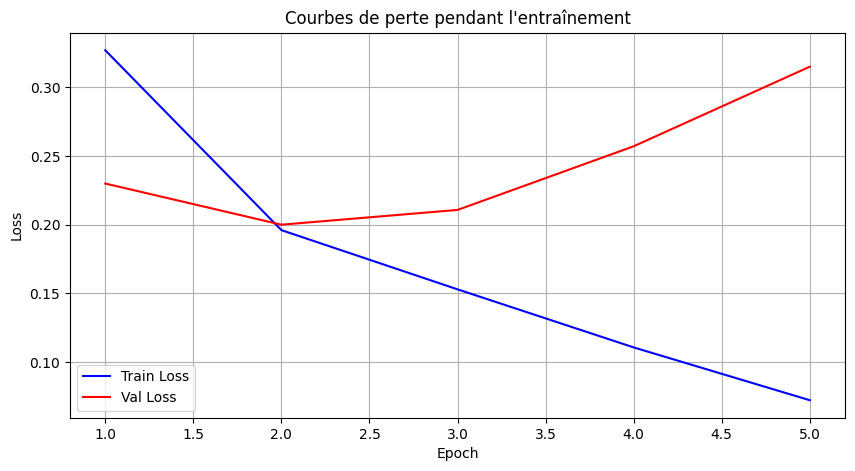

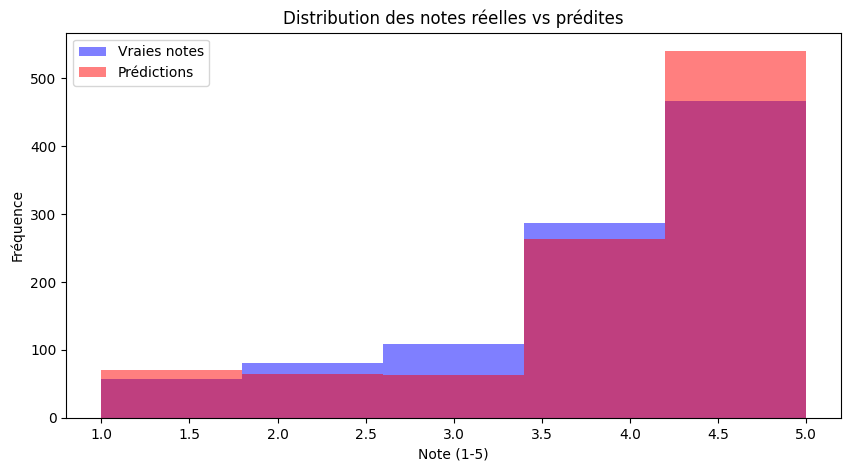

In [ ]:
# Tracé des courbes de perte
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(all_train_loss) + 1), all_train_loss, 'b-', label='Train Loss')
plt.plot(range(1, len(all_val_loss) + 1), all_val_loss, 'r-', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Courbes de perte pendant l\'entraînement')
plt.legend()
plt.grid(True)
plt.show()

# Distribution des prédictions vs valeurs réelles
plt.figure(figsize=(10, 5))
plt.hist(all_true, bins=5, alpha=0.5, label='Vraies notes', color='blue')
plt.hist(all_preds, bins=5, alpha=0.5, label='Prédictions', color='red')
plt.xlabel('Note (1-5)')
plt.ylabel('Fréquence')
plt.title('Distribution des notes réelles vs prédites')
plt.legend()
plt.show()

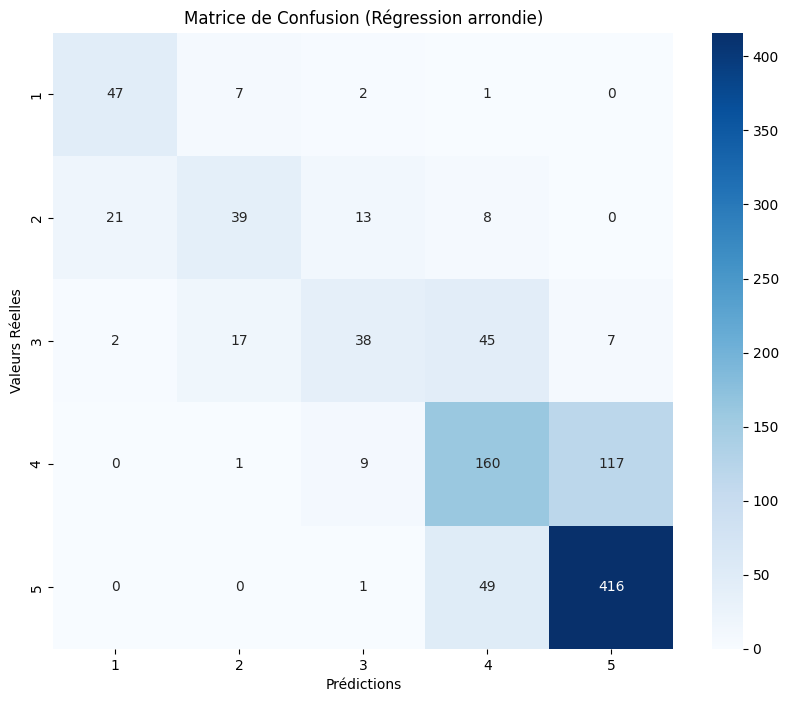

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# 1. Calcul de la matrice de confusion
# On arrondit les prédictions car vous êtes en mode régression
y_pred_rounded = [round(p) for p in all_preds]
y_true = all_true.tolist()

cm = confusion_matrix(y_true, y_pred_rounded)

# 2. Affichage graphique
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[1, 2, 3, 4, 5], 
            yticklabels=[1, 2, 3, 4, 5])

plt.xlabel('Prédictions')
plt.ylabel('Valeurs Réelles')
plt.title('Matrice de Confusion (Régression arrondie)')
plt.show()

## 8. Analyse des erreurs (exemples difficiles)

In [ ]:
# Analyse des cas difficiles
errors = np.abs(np.array(all_true) - np.array(all_preds))
hard_cases = data_test.iloc[np.where(errors > 1)]

print("Exemples de prédictions difficiles (erreur > 1 étoile):")
print("-" * 60)

for i, (idx, row) in enumerate(hard_cases.head(5).iterrows()):
    print(f"\nExemple {i+1}:")
    print(f"  Vraie note: {row['Rating']} | Prédite: {all_preds[data_test.index.get_loc(idx)]}")
    print(f"  Commentaire: {row['Review'][:200]}...")
    print("-" * 60)

Exemples de prédictions difficiles (erreur > 1 étoile):
------------------------------------------------------------

Exemple 1:
  Vraie note: 2 | Prédite: 4
  Commentaire: sure read just got yesterday wait post review place reading past 3 months, stayed sept 14 sept 21. room number 2153. 3rd inclusive vacation, iberostar punta cana barcelo riviera maya, vacationed alot ...
------------------------------------------------------------

Exemple 2:
  Vraie note: 2 | Prédite: 4
  Commentaire: pretty hotel hotel really pretty no doubt girl guest services named marcian somethin like worst seen bad attitude slow restaurants reservations bad english really bad guest services.on hand bartenders...
------------------------------------------------------------

Exemple 3:
  Vraie note: 1 | Prédite: 3
  Commentaire: n't believe reviews read terror tinytown staff fine rooms small defy belief, booked room based positive reviews checked began question people wrote great things, want rent room small ca

## 9. Sauvegarde du modèle

In [ ]:
# Sauvegarde du modèle entraîné
model_path = 'bert_hotel_rating_model_v1.pth'
torch.save({
    'model_state_dict': model.state_dict(),
    'model_id': model_id,
    'r2_score': r2,
    'accuracy': acc_exact,
    'config': {
        'num_classes': num_classes,
        'max_length': max_length,
        'batch_size': batch_size,
        'lr': lr,
        'epochs': epochs
    }
}, model_path)

print(f"Modèle sauvegardé dans: {model_path}")

# Informations mémoire GPU
if torch.cuda.is_available():
    print(f"\nMémoire GPU utilisée:")
    print(f"  Allouée: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
    print(f"  Réservée: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")

Modèle sauvegardé dans: bert_hotel_rating_model.pth

Mémoire GPU utilisée:
  Allouée: 2371.76 MB
  Réservée: 3066.00 MB


## Résumé

Ce notebook implémente un modèle BERT (ModernBERT) pour la prédiction de notes d'hôtels à partir de commentaires.

**Points clés:**
- Utilisation de ModernBERT pour des performances rapides
- Approche CORN pour la régression ordinale
- Mean pooling des embeddings BERT
- Entraînement avec BCEWithLogitsLoss
- Métriques: R², MAE, Accuracy exacte, Accuracy ±1 étoile